# Supplementary Fig. 6d: yield of single-units and multi-units of Buccino's model, the MEArec models and our biophysical model (Kilosort4)

**author**: laquitainesteeve@gmail.com

**purpose**: reproduce panel d of Supplementary Fig. 6: proportion and number of single-units (white) and multi-units (black) sorted with Kilosort4 from the first 10 minutes of Buccino's model (2020), the MEArec models S2 to S5 and our biophysical model of the spontaneous regime (NS). Source data and svg are saved in figures/8_source_data/supp_fig6d/.

**data**: Kilosort4 sortings in `dataset/01_intermediate/sorting/` (Buccino, NS: from DANDI; S2 to S5: `src/pipes/validation/synthetic/sort_ks4.py`). Single-units are the units that Kilosort labels 'good', the others are multi-units. For NS only the units in the cortex (layers 1 to 6) are counted.

**Prerequisites**: the simulations S2-S5 and their Kilosort4 sortings are produced as described in "Prerequisites" of `supp_fig6c.ipynb`.

In [1]:
# SETUP PACKAGES
import os
import warnings
import numpy as np
import pandas as pd
import spikeinterface as si
from matplotlib import pyplot as plt
warnings.simplefilter(action="ignore")

# SET PROJECT PATH
PROJ_PATH = "/home/steeve/steeve/epfl/code/spikebias"
os.chdir(PROJ_PATH)
from src.nodes.validation import firing_rate as fr
from src.nodes.analysis.accuracy import accuracy as acc

# datasets (first 10 minutes), sorted with Kilosort4
DATASETS = ["Buccino", "s2", "s3", "s4", "s5", "NS"]
SORTING_PATHS = {
    "Buccino": "dataset/01_intermediate/sorting/buccino/SortingKS4_10m",
    "s2": "dataset/01_intermediate/sorting/synth2/SortingKS4_10m",
    "s3": "dataset/01_intermediate/sorting/synth3/SortingKS4_10m",
    "s4": "dataset/01_intermediate/sorting/synth4/SortingKS4_10m",
    "s5": "dataset/01_intermediate/sorting/synth5/SortingKS4_10m",
    "NS": "dataset/01_intermediate/sorting/npx_spont/SortingKS4_10m",
}
GROUND_TRUTH_PATHS = {
    "Buccino": "dataset/00_raw/sorting_buccino",
    "s2": "dataset/00_raw/ground_truth_synth2",
    "s3": "dataset/00_raw/ground_truth_synth3",
    "s4": "dataset/00_raw/ground_truth_synth4",
    "s5": "dataset/00_raw/ground_truth_synth5",
    "NS": "dataset/00_raw/ground_truth_npx_spont",
}

# FIGURE SETTINGS
plt.rcParams["font.family"] = "DejaVu Sans"   # the paper's figure was drawn without Arial (matplotlib default font)
plt.rcParams["font.size"] = 6  # 5-7 with Nature neuroscience as reference
plt.rcParams["lines.linewidth"] = 0.5
plt.rcParams["axes.linewidth"] = 0.5
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["xtick.major.width"] = 0.5
plt.rcParams["ytick.major.width"] = 0.5
plt.rcParams["xtick.major.size"] = 3.5 * 1.1
plt.rcParams["ytick.major.size"] = 3.5 * 1.1
savefig_cfg = {"transparent": True, "dpi": 300}

## Count the sorted units

In [2]:
rows = []
for d in DATASETS:
    if d == "NS":
        u = fr.get_sorted_unit_meta(SORTING_PATHS[d])
        u = u[np.isin(u["layer"], ["L1", "L2", "L3", "L2/3", "L2_3", "L4", "L5", "L6"])]       # units in the cortex
        n_single = int((u["kslabel"] == "good").sum()); n_total = len(u)
    else:
        S = si.load_extractor(SORTING_PATHS[d])
        n_single = int((S.get_property("KSLabel") == "good").sum()); n_total = len(S.unit_ids)
    rows.append({"dataset": d, "n_single_units": n_single, "n_multi_units": n_total - n_single, "n_units": n_total, "proportion_single_units": n_single / n_total})
df = pd.DataFrame(rows)
display(df)

,dataset,n_single_units,n_multi_units,n_units,proportion_single_units
0,Buccino,377,163,540,0.698148
1,s2,1115,237,1352,0.824704
2,s3,647,466,1113,0.581312
3,s4,584,795,1379,0.423495
4,s5,600,1117,1717,0.349447
5,NS,184,336,520,0.353846


## Plot, same as the paper's panel d

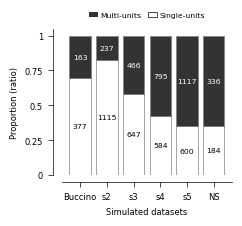

In [3]:
def plot_source_data(df: pd.DataFrame):
    """Stacked bars of the proportion of single-units (white) and multi-units (black); the numbers are the unit counts"""
    fig, ax = plt.subplots(figsize=(2.2, 1.9))
    x = np.arange(len(df))
    ax.bar(x, df["proportion_single_units"], color="white", edgecolor=(0.5, 0.5, 0.5), width=0.8, linewidth=0.5)
    ax.bar(x, 1 - df["proportion_single_units"], bottom=df["proportion_single_units"], color=(0.2, 0.2, 0.2), edgecolor=(0.5, 0.5, 0.5), width=0.8, linewidth=0.5)
    for i, r in df.iterrows():
        ax.text(i, r["proportion_single_units"] / 2 if r["proportion_single_units"] > 0.12 else r["proportion_single_units"] / 2, str(int(r["n_single_units"])), ha="center", va="center", color="k", fontsize=5.5)
        ax.text(i, r["proportion_single_units"] + (1 - r["proportion_single_units"]) / 2, str(int(r["n_multi_units"])), ha="center", va="center", color="w", fontsize=5.5)
    ax.set_xticks(x, df["dataset"])
    ax.set_yticks([0, 0.25, 0.5, 0.75, 1], [0, 0.25, 0.5, 0.75, 1])
    ax.set_ylabel("Proportion (ratio)")
    ax.set_xlabel("Simulated datasets")
    ax.spines["bottom"].set_position(("axes", -0.05))
    ax.yaxis.set_ticks_position("left")
    ax.spines["left"].set_position(("axes", -0.05))
    # legend
    ax.bar([0], [0], color=(0.2, 0.2, 0.2), label="Multi-units")
    ax.bar([0], [0], color="white", edgecolor="k", linewidth=0.5, label="Single-units")
    ax.legend(frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, 1.16), handlelength=1.2, handletextpad=0.3, columnspacing=0.8, fontsize=5.5)
    return fig, ax


fig, ax = plot_source_data(df)

## Save the figure and the source data

In [4]:
os.makedirs("figures/8_source_data/supp_fig6d", exist_ok=True)
plt.savefig("figures/8_source_data/supp_fig6d/supp_fig6d.svg", bbox_inches="tight", **savefig_cfg)
df.to_excel("figures/8_source_data/supp_fig6d/supp_fig6d.xlsx", index=False)

<Figure size 640x480 with 0 Axes>

## Check: replot from the saved source data

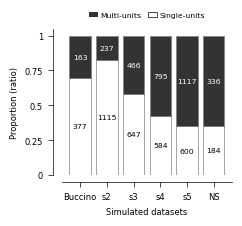

In [5]:
df_loaded = pd.read_excel("figures/8_source_data/supp_fig6d/supp_fig6d.xlsx")
fig, ax = plot_source_data(df_loaded)